In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# read in data
df = pd.read_csv("sleep_clean.csv")
df.head()

,age,bedtime_screen_time_minutes,total_daily_screen_time_hours,doomscroll_sessions_per_night,avg_doomscroll_session_minutes,sleep_hours_per_night,sleep_latency_minutes,number_of_night_wakeups,caffeine_intake_mg_per_day,anxiety_score,...,country_region,primary_device_used_at_night,bedtime_routine_type,uses_night_mode,keeps_phone_in_bedroom,consumes_negative_news_content,uses_sleep_tracking_app,doomscroller,sleep_quality_category,imputed
0,22,13.0,1.85,2,5.4,8.1,19.0,2,155.0,5,...,Germany,Tablet,Meditation/Journaling,1,1,1,0,1,Good,0
1,18,90.0,3.61,3,29.6,7.0,31.0,3,82.0,5,...,India,Smartphone,Meditation/Journaling,0,1,1,0,1,Poor,0
2,37,51.0,5.15,3,15.5,7.1,24.0,2,49.0,2,...,India,Laptop,Reading,0,1,0,1,1,Fair,0
3,27,53.0,3.74,0,51.4,8.4,35.0,0,42.0,6,...,United States,Smartphone,No Fixed Routine,0,1,1,0,0,Fair,0
4,17,67.0,6.09,2,32.2,7.2,19.0,1,76.0,5,...,United States,Smartphone,Watching Videos,0,0,0,0,0,Fair,0


In [4]:
# inspect dataframe shape and dtypes
print("Shape:", df.shape)
display(df.info())

Shape: (960, 30)
<class 'pandas.DataFrame'>
RangeIndex: 960 entries, 0 to 959
Data columns (total 30 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   age                             960 non-null    int64  
 1   bedtime_screen_time_minutes     960 non-null    float64
 2   total_daily_screen_time_hours   960 non-null    float64
 3   doomscroll_sessions_per_night   960 non-null    int64  
 4   avg_doomscroll_session_minutes  960 non-null    float64
 5   sleep_hours_per_night           960 non-null    float64
 6   sleep_latency_minutes           960 non-null    float64
 7   number_of_night_wakeups         960 non-null    int64  
 8   caffeine_intake_mg_per_day      960 non-null    float64
 9   anxiety_score                   960 non-null    int64  
 10  stress_score                    960 non-null    int64  
 11  sleep_quality_score             960 non-null    float64
 12  daytime_fatigue_score         

None

In [5]:
# summary statistics for str variables
display(df.describe(include="str").T)

,count,unique,top,freq
gender,960,3,Male,478
occupation_status,960,5,Employed Full-time,358
country_region,960,10,India,259
primary_device_used_at_night,960,5,Smartphone,673
bedtime_routine_type,960,6,Scrolling Social Media,360
sleep_quality_category,960,3,Good,326


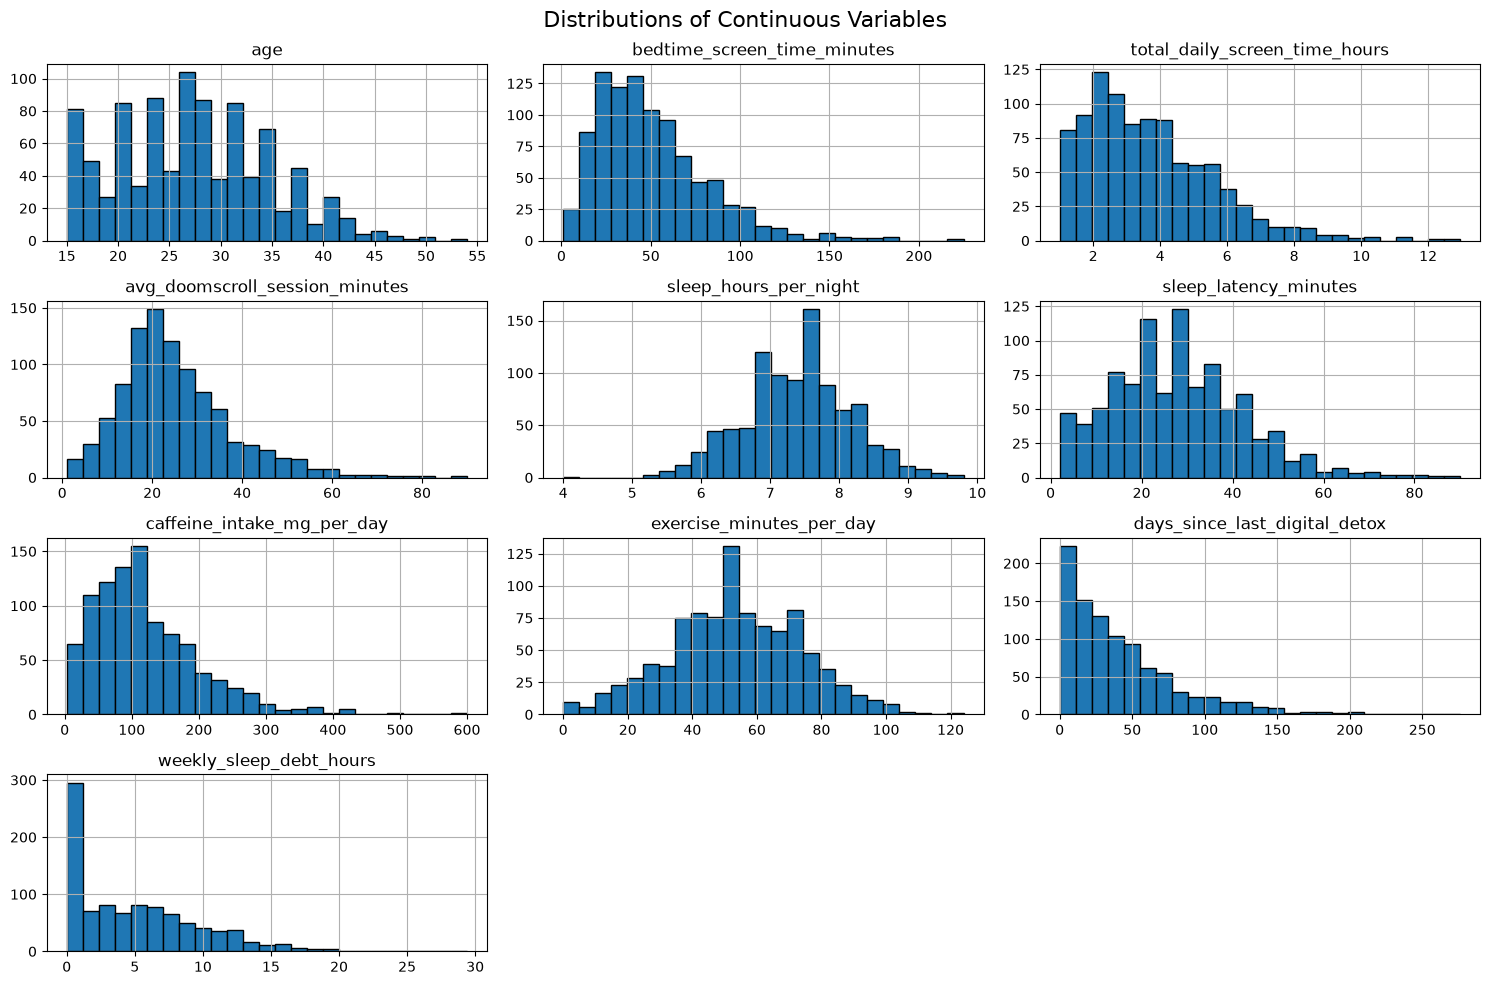

In [6]:
# generate distributions of continuous numeric variables
continuous_cols = [
    "age",
    "bedtime_screen_time_minutes",
    "total_daily_screen_time_hours",
    "avg_doomscroll_session_minutes",
    "sleep_hours_per_night",
    "sleep_latency_minutes",
    "caffeine_intake_mg_per_day",
    "exercise_minutes_per_day",
    "days_since_last_digital_detox",
    "weekly_sleep_debt_hours"
]

df[continuous_cols].hist(
    figsize=(15, 10),
    bins=25,
    edgecolor="black"
)

plt.suptitle("Distributions of Continuous Variables", fontsize=16)
plt.tight_layout()
plt.show()

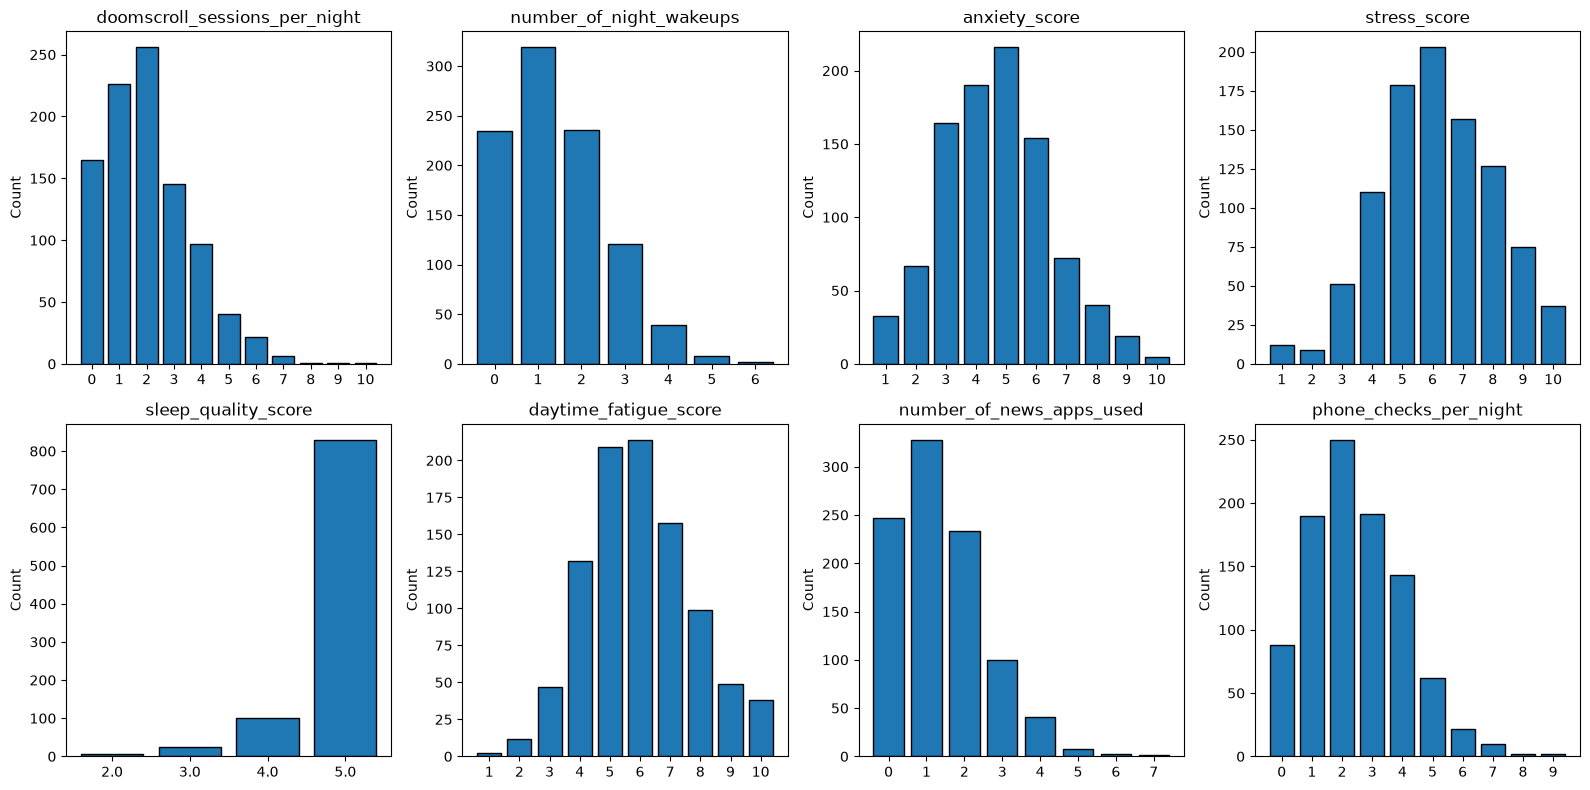

In [7]:
# generate distributions of discrete numeric variables
discrete_cols = [
    "doomscroll_sessions_per_night",
    "number_of_night_wakeups",
    "anxiety_score",
    "stress_score",
    "sleep_quality_score",
    "daytime_fatigue_score",
    "number_of_news_apps_used",
    "phone_checks_per_night"
]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, col in zip(axes.flat, discrete_cols):

    counts = df[col].value_counts().sort_index()

    ax.bar(
        counts.index.astype(str),
        counts.values,
        edgecolor="black"
    )

    ax.set_title(col)
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

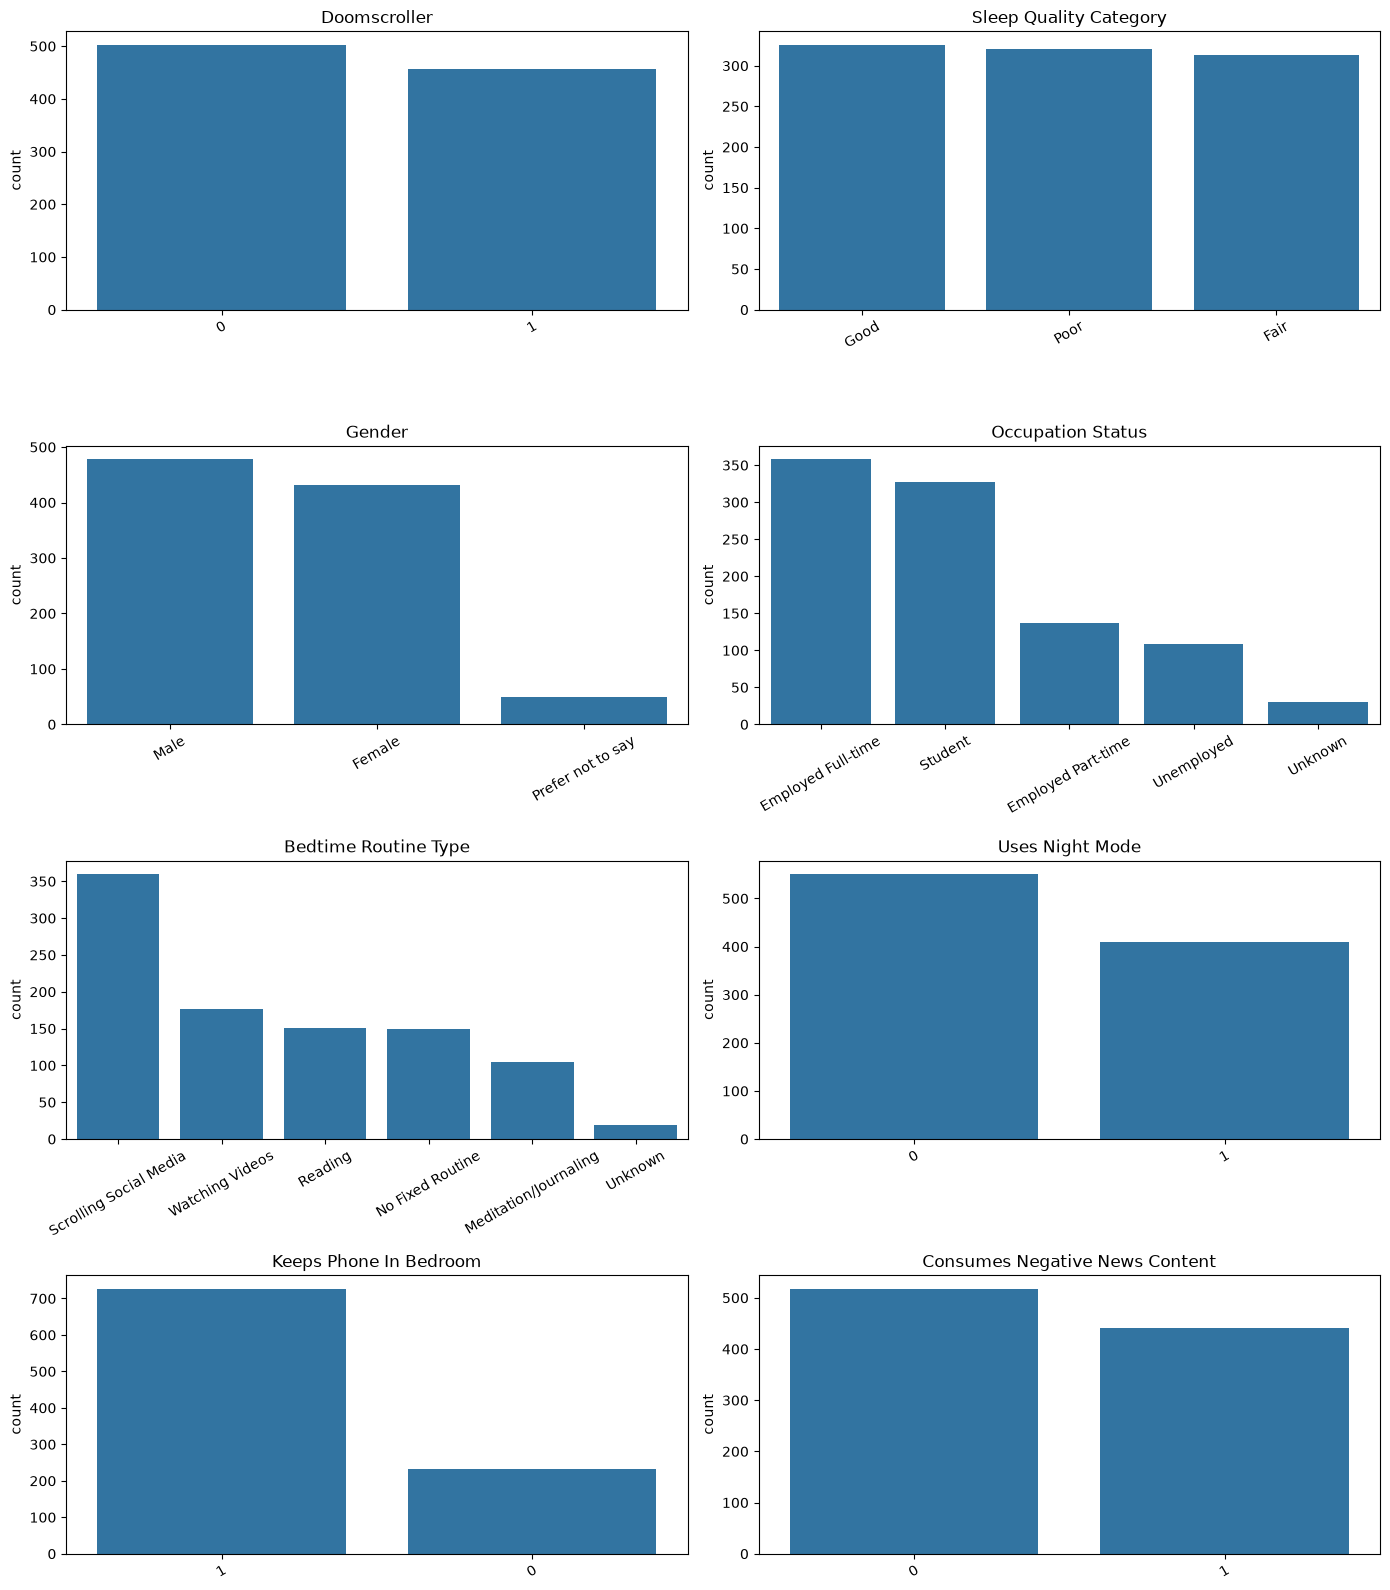

In [8]:
# generate counts for categorical variables
cat_cols = [
    "doomscroller",
    "sleep_quality_category",
    "gender",
    "occupation_status",
    "bedtime_routine_type",
    "uses_night_mode",
    "keeps_phone_in_bedroom",
    "consumes_negative_news_content"
]

fig, axes = plt.subplots(4, 2, figsize=(14, 16))

for ax, col in zip(axes.flat, cat_cols):
    sns.countplot(
        data=df,
        x=col,
        order=df[col].value_counts().index,
        ax=ax
    )
    ax.set_title(col.replace("_", " ").title())
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

,Correlation with Sleep Quality
daytime_fatigue_score,-0.449824
bedtime_screen_time_minutes,-0.420659
doomscroll_sessions_per_night,-0.385753
sleep_latency_minutes,-0.384771
weekly_sleep_debt_hours,-0.334700
number_of_night_wakeups,-0.290153
total_daily_screen_time_hours,-0.233855
phone_checks_per_night,-0.214028
doomscroller,-0.177613
anxiety_score,-0.145446


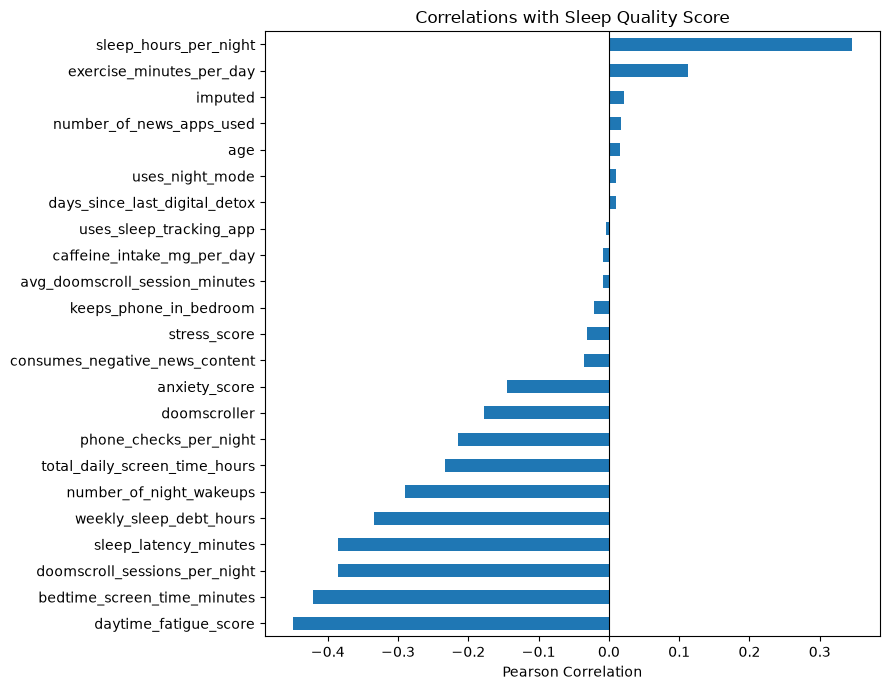

In [9]:
# select numerical columns (excluding respondent ID)
numeric_cols = df.select_dtypes(include="number").columns.drop(
    "respondent_id", errors="ignore"
)

# calculate correlations
sleep_corr = (
    df[numeric_cols]
    .corr()["sleep_quality_score"]
    .drop("sleep_quality_score")
    .sort_values()
)

display(sleep_corr.to_frame("Correlation with Sleep Quality"))

plt.figure(figsize=(9, 7))
sleep_corr.plot(kind="barh")
plt.xlabel("Pearson Correlation")
plt.title("Correlations with Sleep Quality Score")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

In [10]:
# calculate outcome summaries for doomscroller vs non-doomscroller
outcomes = [
    "sleep_hours_per_night",
    "sleep_latency_minutes",
    "sleep_quality_score",
    "daytime_fatigue_score",
    "number_of_night_wakeups",
    "weekly_sleep_debt_hours"
]

display(
    df.groupby("doomscroller")[outcomes]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

sleep_hours_per_night                    sleep_latency_minutes  \
                             count  mean median   std                 count   
doomscroller                                                                  
0                              503  7.53    7.5  0.71                   503   
1                              457  7.27    7.3  0.81                   457   

                                  sleep_quality_score        ...  \
               mean median    std               count  mean  ...   
doomscroller                                                 ...   
0             22.88   22.0  11.57                 503  4.91  ...   
1             33.52   33.0  15.44                 457  4.74  ...   

             daytime_fatigue_score       number_of_night_wakeups               \
                            median   std                   count  mean median   
doomscroller                                                                    
0                              6.0  1.67                     503  1.18    1.0   
1                              6.0  1.84                     457  1.68    2.0   

                   weekly_sleep_debt_hours                     
               std                   count  mean median   std  
doomscroller                                                   
0             1.03                     503  4.16    3.1  4.24  
1             1.26                     457  5.76    5.0  5.00  

[2 rows x 24 columns]

In [11]:
# separate phone and sleep variables
phone_vars = [
    "bedtime_screen_time_minutes",
    "total_daily_screen_time_hours",
    "doomscroll_sessions_per_night",
    "avg_doomscroll_session_minutes",
    "phone_checks_per_night"
]

sleep_vars = [
    "sleep_hours_per_night",
    "sleep_latency_minutes",
    "sleep_quality_score",
    "number_of_night_wakeups",
    "daytime_fatigue_score",
    "weekly_sleep_debt_hours"
]

In [12]:
# scatterplot of bedtime screen time vs. sleep duration
import plotly.express as px

fig = px.scatter(
    df,
    x="bedtime_screen_time_minutes",
    y="sleep_hours_per_night",
    opacity=0.4,
    title="Bedtime Screen Time vs. Sleep Duration",
    labels={
        "bedtime_screen_time_minutes": "Bedtime Screen Time (minutes)",
        "sleep_hours_per_night": "Sleep Duration (hours)"
    }
)

fig.show()

In [13]:
# scatterplot of bedtime screen time vs. sleep latency minutes

import plotly.express as px

fig = px.scatter(
    df,
    x="bedtime_screen_time_minutes",
    y="sleep_latency_minutes",
    opacity=0.4,
    title="Bedtime Screen Time vs. Sleep Latency Minutes",
    labels={
        "bedtime_screen_time_minutes": "Bedtime Screen Time (minutes)",
        "sleep_hours_per_night": "Sleep Duration (hours)"
    }
)

fig.show()

In [16]:
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy.stats import gaussian_kde

# KDE and ECDF of sleep duration by doomscroller status
fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=("KDE", "ECDF"),
    horizontal_spacing=0.10
)

for group, subset in df.groupby("doomscroller"):
    values = subset["sleep_hours_per_night"].dropna().to_numpy()

    if len(values) == 0:
        continue

    # KDE
    if len(values) >= 2 and np.std(values) > 0:
        kde = gaussian_kde(values)
        grid = np.linspace(values.min(), values.max(), 200)

        fig.add_trace(
            go.Scatter(
                x=grid,
                y=kde(grid),
                mode="lines",
                name=str(group),
                legendgroup=str(group)
            ),
            row=1,
            col=1
        )

    # ECDF
    sorted_values = np.sort(values)
    ecdf_y = np.arange(1, len(values) + 1) / len(values)

    fig.add_trace(
        go.Scatter(
            x=sorted_values,
            y=ecdf_y,
            mode="lines",
            line_shape="hv",
            name=str(group),
            legendgroup=str(group),
            showlegend=False
        ),
        row=1,
        col=2
    )

fig.update_xaxes(
    title_text="Sleep Duration (hours)",
    row=1, col=1
)

fig.update_xaxes(
    title_text="Sleep Duration (hours)",
    row=1, col=2
)

fig.update_yaxes(
    title_text="Estimated Density",
    row=1, col=1
)

fig.update_yaxes(
    title_text="Cumulative Proportion",
    range=[0, 1.05],
    row=1, col=2
)

fig.update_layout(
    title="Sleep Duration by Doomscroller Status",
    legend_title="Doomscroller",
    width=1100,
    height=450,
    template="plotly_white"
)

fig.show()

In [15]:
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy.stats import gaussian_kde

comparisons = [
    ("sleep_latency_minutes", "doomscroller"),
    ("sleep_quality_score", "doomscroller"),
    ("daytime_fatigue_score", "doomscroller"),
    ("weekly_sleep_debt_hours", "doomscroller"),
    ("bedtime_screen_time_minutes", "sleep_quality_category"),
    ("sleep_hours_per_night", "keeps_phone_in_bedroom"),
    ("sleep_latency_minutes", "uses_night_mode"),
    ("sleep_quality_score", "consumes_negative_news_content")
]

for outcome, group_col in comparisons:

    fig = make_subplots(
        rows=1,
        cols=2,
        subplot_titles=("KDE", "ECDF"),
        horizontal_spacing=0.10
    )

    all_values = df[outcome].dropna()
    grid = np.linspace(all_values.min(), all_values.max(), 200)

    for group, subset in df.groupby(group_col):

        values = subset[outcome].dropna().to_numpy()

        if len(values) == 0:
            continue

        # ECDF: sort values and calculate cumulative proportions
        sorted_values = np.sort(values)
        ecdf_y = np.arange(1, len(values) + 1) / len(values)

        # KDE: only if enough variation exists
        if len(values) >= 2 and np.std(values) > 0:

            kde = gaussian_kde(values)

            fig.add_trace(
                go.Scatter(
                    x=grid,
                    y=kde(grid),
                    mode="lines",
                    name=str(group),
                    legendgroup=str(group)
                ),
                row=1,
                col=1
            )

        # ECDF
        fig.add_trace(
            go.Scatter(
                x=sorted_values,
                y=ecdf_y,
                mode="lines",
                line_shape="hv",
                name=str(group),
                legendgroup=str(group),
                showlegend=False
            ),
            row=1,
            col=2
        )

    fig.update_xaxes(
        title_text=outcome.replace("_", " ").title(),
        row=1, col=1
    )

    fig.update_xaxes(
        title_text=outcome.replace("_", " ").title(),
        row=1, col=2
    )

    fig.update_yaxes(
        title_text="Estimated Density",
        row=1, col=1
    )

    fig.update_yaxes(
        title_text="Cumulative Proportion",
        range=[0, 1.05],
        row=1, col=2
    )

    fig.update_layout(
        title=f"{outcome.replace('_', ' ').title()} by {group_col.replace('_', ' ').title()}",
        legend_title=group_col.replace("_", " ").title(),
        width=1100,
        height=450,
        template="plotly_white"
    )

    fig.show()